In [ ]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit
import importlib
import pprint

plt.rcParams['font.size']   = 18
who = [
    "BII_S9",
    "BIV_S8",
    "BIV_S9",
    "BIV_S10"
]

In [ ]:
colors = plt.cm.Reds(np.linspace(0.5, 0.9, 3))
aesthetics_dict = {
    "BII_S9": ["15 mM LVs", "grey"],
    "BIV_S8": ["15 mM LVs + 50 µM aSyn", colors[0]],
    "BIV_S9": ["15 mM LVs + 75 µM aSyn", colors[1]],
    "BIV_S10": ["15 mM LVs + 100 µM aSyn", colors[2]],
}

For sample 15 mM LVs
EDP total    : 0.3049
EDP HG       : 1.8252
EDP TG       : 1.5203
HG asymmetry : 0.2448
HG/TG ratio  : 1.2006
For sample 15 mM LVs + 50 µM aSyn
EDP total    : 0.3511
EDP HG       : 1.8336
EDP TG       : 1.4825
HG asymmetry : 0.3529
HG/TG ratio  : 1.2369
For sample 15 mM LVs + 75 µM aSyn
EDP total    : 0.3533
EDP HG       : 1.8582
EDP TG       : 1.5049
HG asymmetry : 0.3984
HG/TG ratio  : 1.2347
For sample 15 mM LVs + 100 µM aSyn
EDP total    : 0.2557
EDP HG       : 1.7596
EDP TG       : 1.5039
HG asymmetry : 0.3094
HG/TG ratio  : 1.1700


NameError: name 'ax' is not defined

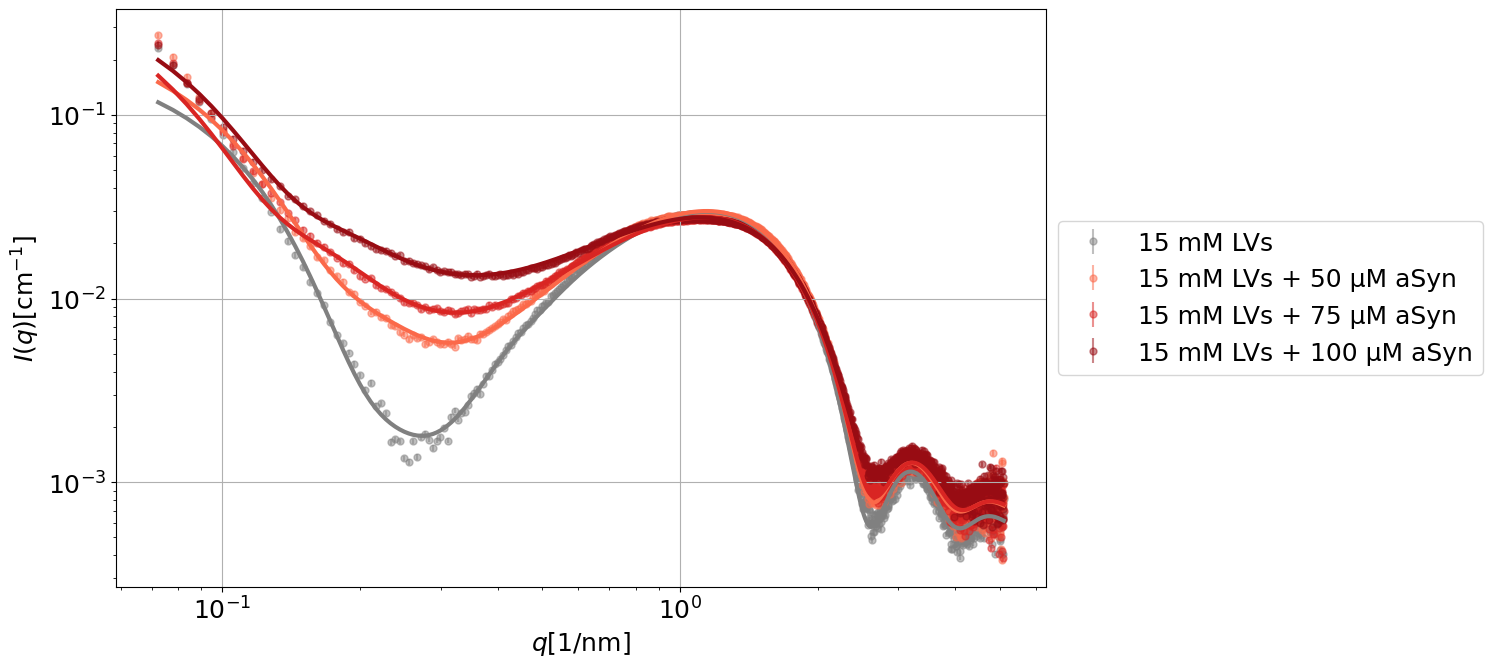

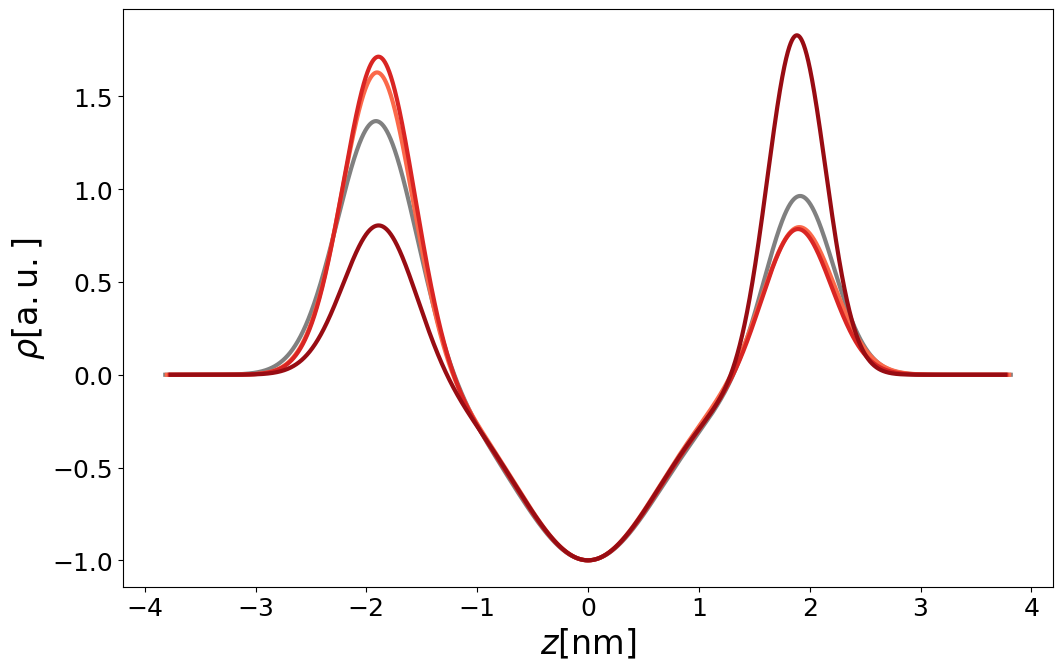

In [ ]:
fit_function_name = "ULV_spheric_asym_C4" 
fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
# fit_function_name = "ULV_ellipsoid_asym_C4"
# fit_function = lambda q,  R,  sigma_R,     eps, sigma_eps,  rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,    scale, c4: fit.ULV_ellipsoid_asym(q, R,  sigma_R,     eps, sigma_eps,  rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,    scale,   0, 0, c4)

                                                              
f = plt.figure(figsize=(12, 7.5))
for sample in who:
    block = sample.split("_")[0]
    block_path = BM29.blockpath(block)
    dir_names = [x.name for x in block_path.iterdir()]
    for dir_name in dir_names:
        if dir_name[:-13].endswith(sample):
            sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
            q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)
    
    mask = (q >= 0.07) & (q <= 5.1)
    q    = q[mask]
    I    = I[mask]
    Ierr = Ierr[mask]
    Ierr_op = BM29.op_error_classic(q, I) 

    I_fit = fit_function(q, *BM29.best_fits[sample][fit_function_name][1])
    plt.errorbar(q, I, Ierr_op, marker="o", markersize=5, ecolor=aesthetics_dict[sample][1], color=aesthetics_dict[sample][1], markeredgewidth=1, alpha=0.5, ls="None", label=aesthetics_dict[sample][0], zorder=1) 
    plt.loglog(q, I_fit, color=aesthetics_dict[sample][1], lw=3)

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q) [\\mathrm{cm}^{-1}]$')
plt.grid()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')

def EDP_plot(fit_function_name, who, aesthetics_dict):
    param_list = []
    for sample in who:
        if fit_function_name == "ULV_spheric_asym_C4":
            rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h = BM29.best_fits[sample][fit_function_name][1][2:8]
        if fit_function_name == "ULV_ellipsoid_asym_C4": 
            rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h = BM29.best_fits[sample][fit_function_name][1][4:10]
        if fit_function_name == "flat_asym_C4_q0p7":
            rho_h1, rho_h2 = BM29.best_fits[sample][fit_function_name][1][3:5]
            sigma_h1, sigma_h2, sigma_c = BM29.best_fits[sample][fit_function_name][1][0:3]
            z_h = BM29.best_fits[sample][fit_function_name][1][5]
        EDP_plot_together_input = [sample, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, aesthetics_dict[sample][1]]
        param_list.append(EDP_plot_together_input)

        EDP_tot, EDP_hg, EDP_tg, EDP_hg_asym, EDP_hg_tg = fit.EDP_analysis(EDP_plot_together_input[1:7])
        print(f"For sample {aesthetics_dict[sample][0]}")
        print(f"EDP total    : {EDP_tot:.4f}")
        print(f"EDP HG       : {EDP_hg:.4f}")
        print(f"EDP TG       : {EDP_tg:.4f}")
        print(f"HG asymmetry : {EDP_hg_asym:.4f}")
        print(f"HG/TG ratio  : {EDP_hg_tg:.4f}")

    fig = fit.EDP_plot_together(param_list, "")
    return fig

fig = EDP_plot("ULV_spheric_asym_C4", who, aesthetics_dict)

target_folder = Path("C:/Users/riko05/Documents/8. SoSe 26/Code/BM29_data_and_analysis_2026/analysis_BM29_July2026/Results_and_Figures/Aug24/Figure_7")
fig.savefig(target_folder / "EDPs_Fig7.png", dpi=400, bbox_inches='tight', pad_inches=0.05)
f.savefig(target_folder / "Curves_and_Fits_Fig7.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

In [ ]:
fit_function_name = "ULV_spheric_asym_C4" 
fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
for sample in who:   
    # sample = "BIV_S10"
    print(aesthetics_dict[sample][0])
    block = sample.split("_")[0]
    block_path = BM29.blockpath(block)
    dir_names = [x.name for x in block_path.iterdir()]
    for dir_name in dir_names:
        if dir_name[:-13].endswith(sample):
            sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
            q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)

    q     = q
    I     = I
    I_err_Poisson = BM29.op_error_classic(q, I)

    # ========================== Parameters ==========================
    R = 18
    sigma_R = 7
    rho_h1 = 2.7
    rho_h2 = 1.8
    sigma_h1 = 0.2
    sigma_h2 = 0.3
    sigma_c = 0.75
    z_h = 1.75
    c4 = 0
    scale = 0.00013965

    # ========================== Setting Bounds ==============================
    # p0           = [   R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale] #,      c2,      c3,      c4]
    # lower_bounds = [   9,          3,      1.0,      1.0,       0.15,      0.15,      0.5,    1.5,       0] #,       0,       0, -np.inf]
    # upper_bounds = [  30,          9,      2.5,      2.5,        0.6,       0.6,      1.0,      2,     0.2] #,       4,     0.5, +np.inf]

    p0           = [   R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      c4]
    lower_bounds = [   0,          0,      1.0,      1.4,       0.13,      0.13,      0.5,    1.5,       0,       0] #,       0,       0, -np.inf]
    upper_bounds = [  17,         17,      1.5,      3.5,        0.7,       0.7,      1.0,      2,   0.001,       1] #,       4,     0.5, +np.inf]
    i = 0
    while i < 4:
        p0 = np.random.uniform(lower_bounds, upper_bounds)

        #======================== Fit ===========================================
        popt, pcov = curve_fit(fit_function, q, I, sigma=I_err_Poisson, maxfev=10000, p0=p0, bounds = (lower_bounds, upper_bounds))

        param_names = ["R_fit", "sigma_R_fit", "rho_h1_fit", "rho_h2_fit", "sigma_h1_fit", "sigma_h2_fit", "sigma_c_fit", "z_h_fit", "scale_fit", "c4_fit"]
        perr = np.sqrt(np.diag(pcov))
        fit_lib_entry = "["
        for name, value in zip(param_names, popt):
            globals()[name] = value
            fit_lib_entry += f"{value:.4g}, "
        fit_lib_entry = fit_lib_entry[:-2]
        fit_lib_entry += "]"
        print(fit_lib_entry)
        chi2, info_text_print = fit.all_info(q, I, I_err_Poisson, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
        # print(info_text_print)
        print(chi2)
        print("\n")
        i += 1

15 mM LVs
[9.344, 6.31, 1.084, 2.922, 0.6091, 0.1616, 1, 1.805, 0.0003322, 5.461e-19]
140.73162167522398


[9.345, 6.31, 1.084, 2.922, 0.6092, 0.1616, 1, 1.805, 0.0003323, 9.915e-20]
140.73162161608204


[9.345, 6.31, 1.084, 2.922, 0.6092, 0.1616, 1, 1.805, 0.0003322, 7.006e-32]
140.73162162252822


[9.345, 6.31, 1.084, 2.922, 0.6092, 0.1616, 1, 1.805, 0.0003322, 4.915e-25]
140.73162160587418


15 mM LVs + 50 µM aSyn
[10.31, 5.378, 1, 2.377, 0.5402, 0.2465, 1, 1.795, 0.0003012, 1.499e-39]
185.68378040428124


[10.31, 5.377, 1, 2.377, 0.5402, 0.2465, 1, 1.795, 0.0003011, 4.208e-36]
185.6837808104421


[0.0005837, 0.0003279, 1.5, 3.5, 0.1713, 0.1712, 0.57, 1.718, 0.001, 0.0001137]
597.9228014266862


[1.387e-20, 17, 1.5, 3.256, 0.168, 0.13, 0.5625, 1.995, 0.0001926, 9.159e-46]
172.0840162802059


15 mM LVs + 75 µM aSyn
[7.671, 6.605, 1, 3.455, 0.5136, 0.1782, 1, 1.806, 0.0003185, 1.554e-29]
117.28253421663084


[7.672, 6.605, 1, 3.455, 0.5136, 0.1782, 1, 1.806, 0.0003185, 2.282e-28]
117.

In [ ]:
fit_function_name = "ULV_sph_asym_prot_layer"
fit_function = lambda q, R, sigma_R, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, z_h3, sigma_h3, rho_h3, scale: fit.ULV_sph_asym_prot_layer(q, R, sigma_R, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, z_h3, sigma_h3, rho_h3, scale, 0, 0, 0)
DAY = "Aug19"
sample = "BIV_S10"
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)

q     = q
I     = I
I_err_op = BM29.op_error_classic(q, I)

# ========================== Parameters ==========================
R = 10
sigma_R = 5.5  # BEST FROM SPHERICAL ASYM FIT
rho_h1 = 1.8
rho_h2 = 1.15
sigma_h1 = 0.3
sigma_h2 = 0.44
sigma_c = 0.5
z_h = 1.76
z_h3 = 2.9
sigma_h3 = 0.3
rho_h3 = 0.5
scale = 5e-7
# ========================== Setting Bounds ==============================
p0           = [        R,  sigma_R,       rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,  z_h3, sigma_h3,   rho_h3,    scale] # ,   c2,   c3,       c4]
lower_bounds = [        9,        2,          0.8,    1.0,        0.4,      0.1,      0.7,      1.7,     3,      0.7,      0.0,        0] #,    0,    0,  -np.inf]
upper_bounds = [       15,        8,          1.0,    2.5,        0.6,      0.3,      1.2,      1.9,     5,      1.2,      2.0,   0.0001] # ,  0.2,  0.5,  +np.inf]


chi2 = 1e6
chi2_goal = 5
i = 0
while i < 3:
    print(f"Iteration {i}, current chi2 = {chi2:.4g}")
    print("Current params: ", p0)
    p0 = np.random.uniform(lower_bounds, upper_bounds)

    #======================== Fit ===========================================
    popt, pcov = curve_fit(fit_function, q, I, sigma=I_err_op, maxfev=10000, p0=p0, bounds = (lower_bounds, upper_bounds))

    param_names = ["R_fit", "sigma_R_fit", "rho_h1_fit", "rho_h2_fit",
                "sigma_h1_fit", "sigma_h2_fit", "sigma_c_fit","z_h_fit", "z_h3_fit", "sigma_h3_fit", "rho_h3_fit", "scale_fit"]

    perr = np.sqrt(np.diag(pcov))
    fit_lib_entry = "["
    for name, value in zip(param_names, popt):
        globals()[name] = value
        fit_lib_entry += f"{value:.4g}, "
    fit_lib_entry = fit_lib_entry[:-2]
    fit_lib_entry += "]"
    print(fit_lib_entry)
    print(chi2)
    print("\n")
    chi2, info_text_print = fit.all_info(q, I, I_err_op, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)


    this_file = Path(__file__).resolve()
    analysis_BM29_July2026 = this_file.parent.parent
    target_folder = analysis_BM29_July2026 / "Results_and_Figures" / DAY / f"fit_{fit_function_name}"
    if not target_folder.exists():
        target_folder.mkdir()

    # print("Fit successful with chi2 = ", chi2)
    # print(info_text_print)
    # with open(target_folder/f"info_texts_{DAY}.txt", "a", encoding="utf-8") as k:
    #     k.write(f"\n\n{BM29.sample_dict[sample]} using {fit_function_name} with IRP fit nr. {i}\n" + info_text_print + "\n" + fit_lib_entry + "\n###########################################\n")

    #=========================== Plot ===========================================
    q_fit = np.linspace(min(q), max(q), 1000)
    plt.close("all")
    plt.figure(figsize=(12, 7.5))
    plt.errorbar(q, I, I_err_op, marker="o", markersize=3,markeredgewidth=1,ecolor="Blue",      markeredgecolor='Blue',      markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
    plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
    plt.loglog(q_fit, fit_function(q_fit, R,  sigma_R,       rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,  z_h3, sigma_h3,   rho_h3,    scale), color='orange', label='initial guess')

    plt.xlabel('$q [1/\\mathrm{nm}]$')
    plt.ylabel('$I(q) [\\mathrm{cm}^{-1}]$')
    plt.title(f'{BM29.sample_dict[sample]} \nusing {fit_function_name} (improv. Poisson error)')
    plt.grid(True)
    legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
    legend.set_title(info_text_print)
    plt.tight_layout()
    # plt.savefig(target_folder / f"{sample}_{fit_function_name}_IRP{i}_{DAY}.png",dpi=400, bbox_inches='tight', pad_inches=0.05)

    fig=fit.EDP_plot(R_fit, sigma_h1_fit, sigma_h2_fit, sigma_c_fit, rho_h1_fit, rho_h2_fit, z_h_fit, z_h_fit, info_text_print,  f'{BM29.sample_dict[sample]} using {fit_function_name} nr. {i}', z_h3_fit, sigma_h3_fit, rho_h3_fit)
    # fig.savefig(target_folder / f"EDP_{sample}_{fit_function_name}_IRP{i}.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

    i += 1


Iteration 0, current chi2 = 1e+06
Current params:  [10, 5.5, 1.8, 1.15, 0.3, 0.44, 0.5, 1.76, 2.9, 0.3, 0.5, 5e-07]


Computing I(q):   0%|                                  | 0/1000 [00:00<?, ?it/s]


KeyboardInterrupt: 

15 mM LVs
[0.2718, 0.3083, 0.6172, 1, 1.458, 1.908, 0.04784, 0.0005077]
Fit results with 1σ uncertainties:

sigma_h1_fit = 0.27176 ± 0.047717
sigma_h2_fit = 0.30827 ± 0.055445
sigma_tail_fit = 0.61718 ± 0.0067095
rho_h1_fit = 1 ± 0.14768
rho_h2_fit = 1.458 ± 0.088109
eps_head_fit = 1.9082 ± 0.0040996
scale_fit = 0.047839 ± 0.0030171
c4_fit = 0.0005077 ± 2.1768e-05
chi2 = 9.3469


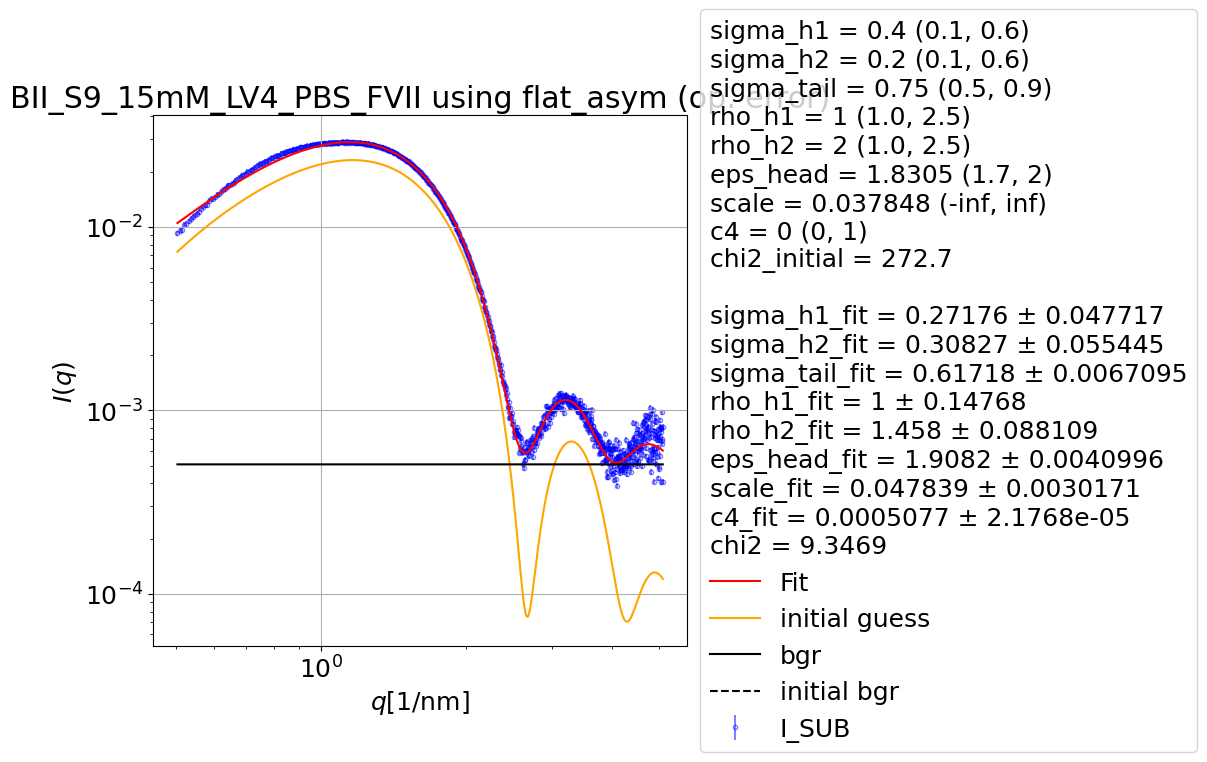

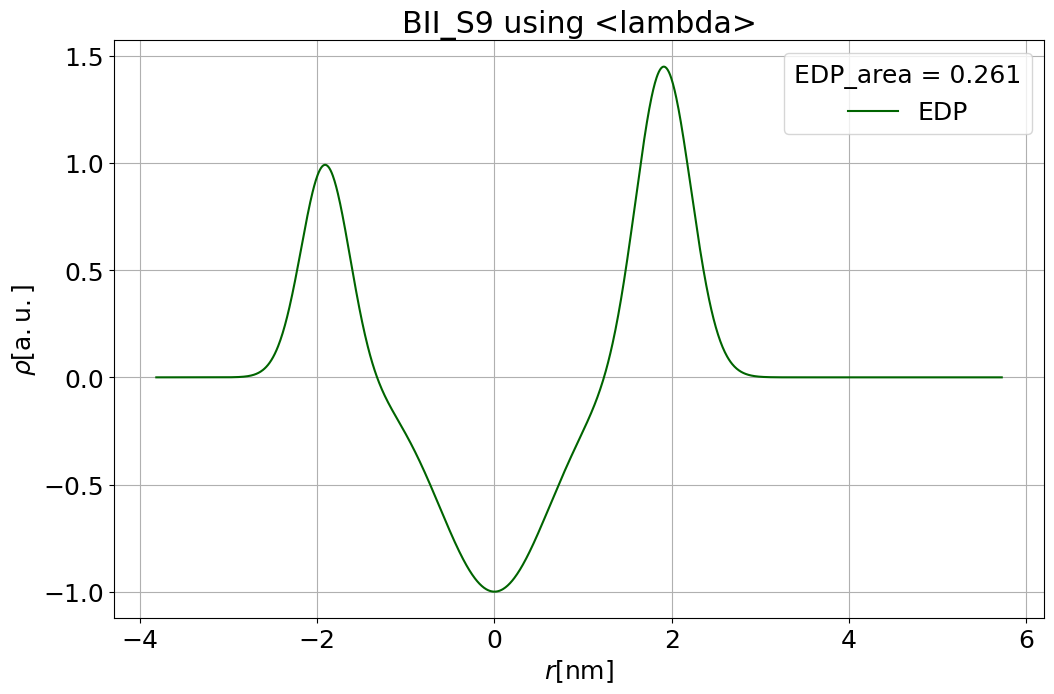

15 mM LVs + 50 µM aSyn
[0.2588, 0.3489, 0.6203, 1, 1.629, 1.891, 0.04236, 0.0006425]
Fit results with 1σ uncertainties:

sigma_h1_fit = 0.25876 ± 0.013811
sigma_h2_fit = 0.34889 ± 0.016874
sigma_tail_fit = 0.62032 ± 0.009417
rho_h1_fit = 1 ± 0.058566
rho_h2_fit = 1.6293 ± 0.032808
eps_head_fit = 1.8913 ± 0.0042789
scale_fit = 0.042363 ± 0.0018551
c4_fit = 0.00064251 ± 9.7606e-06
chi2 = 9.7284


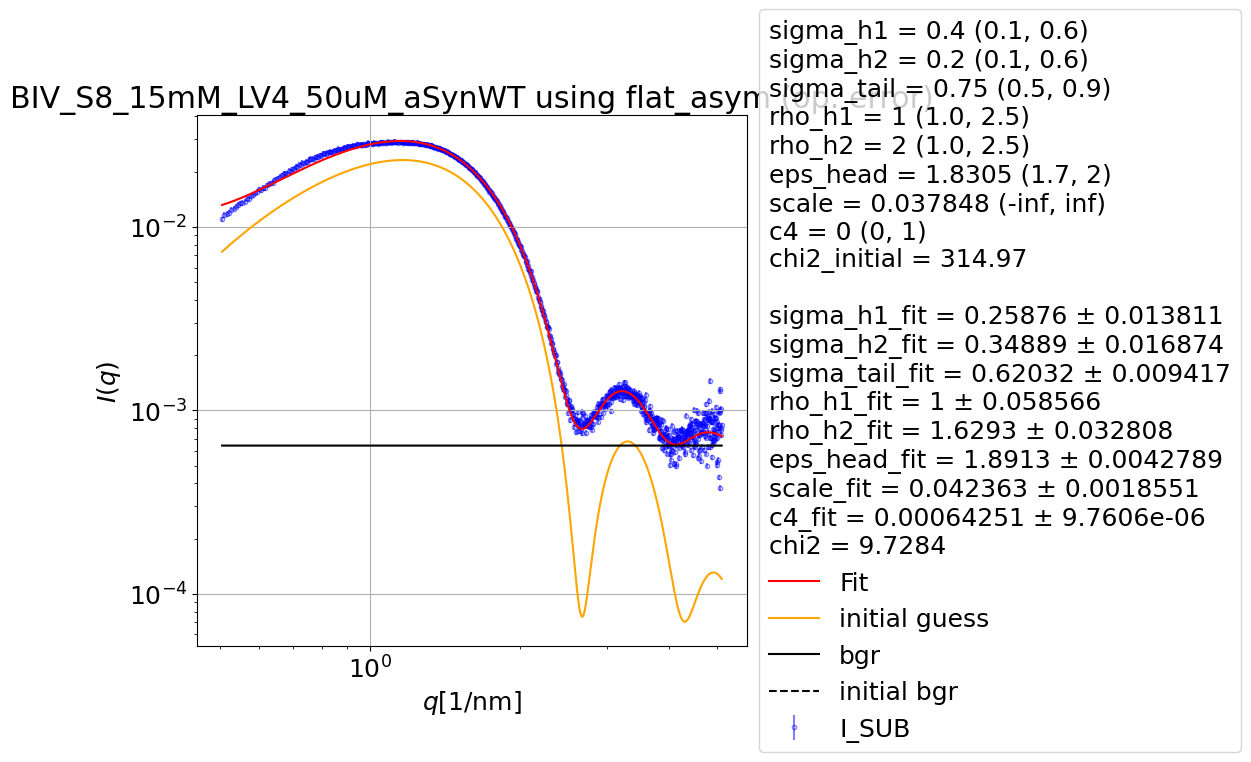

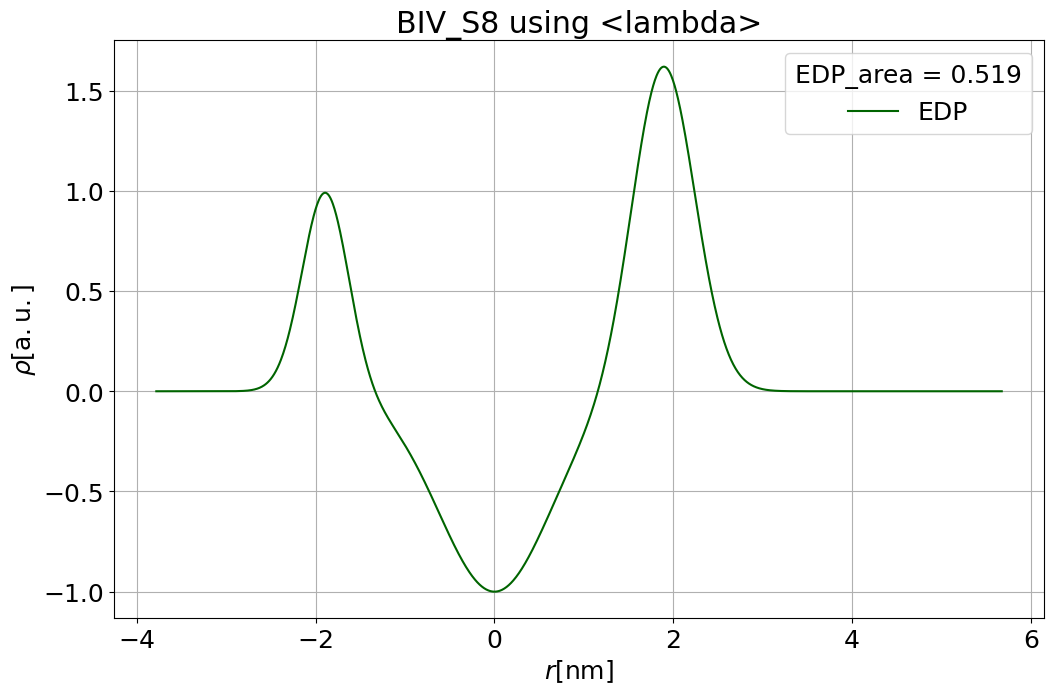

15 mM LVs + 75 µM aSyn
[0.3971, 0.4128, 0.9, 1, 2.013, 1.809, 0.02892, 0.0006695]
Fit results with 1σ uncertainties:

sigma_h1_fit = 0.39708 ± 0.022314
sigma_h2_fit = 0.41285 ± 0.0147
sigma_tail_fit = 0.9 ± 0.082964
rho_h1_fit = 1 ± 0.06037
rho_h2_fit = 2.0132 ± 0.08893
eps_head_fit = 1.8088 ± 0.014721
scale_fit = 0.028921 ± 0.0015407
c4_fit = 0.00066955 ± 6.6491e-06
chi2 = 10.807


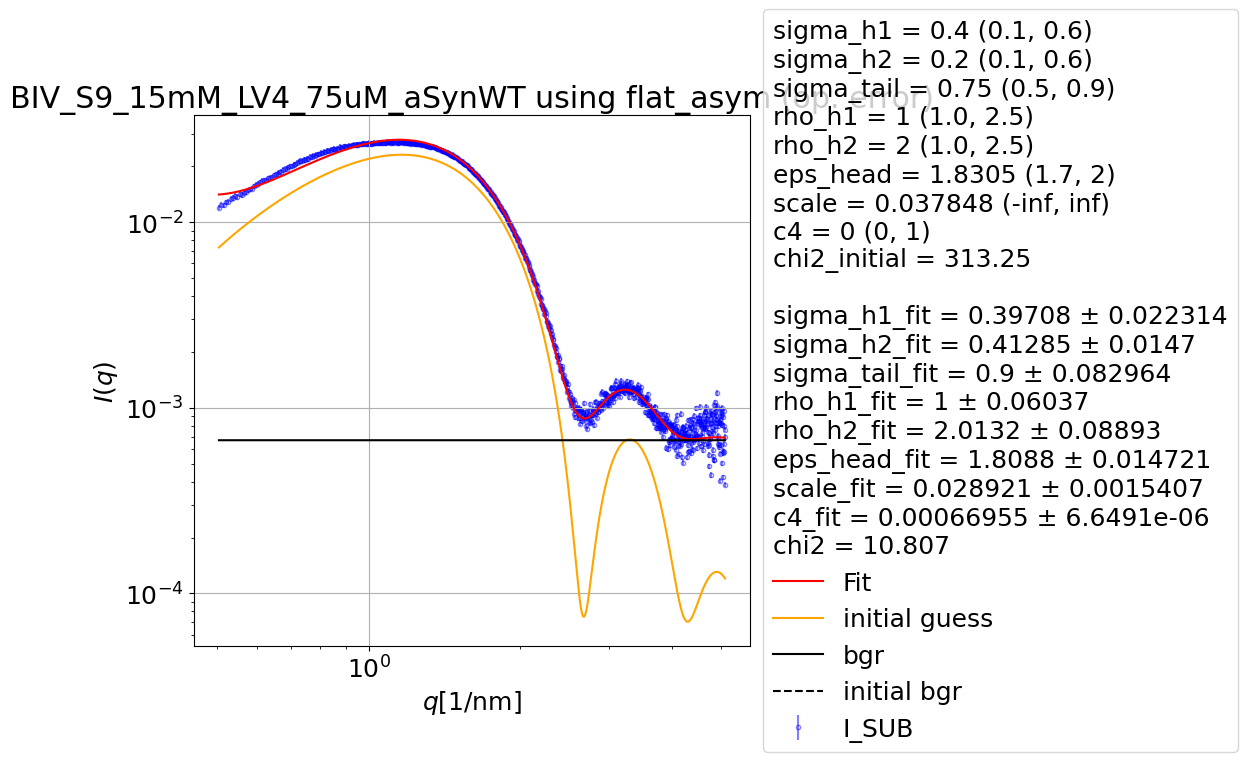

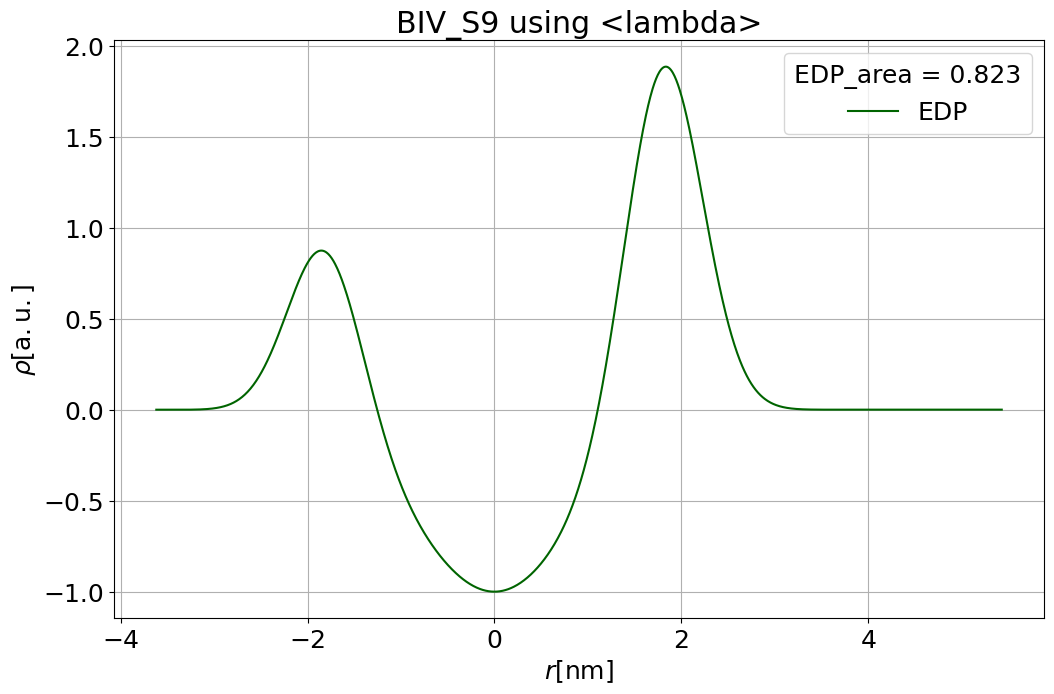

15 mM LVs + 100 µM aSyn
[0.3849, 0.3986, 0.9, 1, 2.275, 1.81, 0.02611, 0.0007729]
Fit results with 1σ uncertainties:

sigma_h1_fit = 0.38492 ± 0.019707
sigma_h2_fit = 0.3986 ± 0.011393
sigma_tail_fit = 0.9 ± 0.07003
rho_h1_fit = 1 ± 0.049839
rho_h2_fit = 2.2748 ± 0.075833
eps_head_fit = 1.8101 ± 0.011895
scale_fit = 0.026115 ± 0.0011612
c4_fit = 0.00077291 ± 6.4434e-06
chi2 = 6.8916


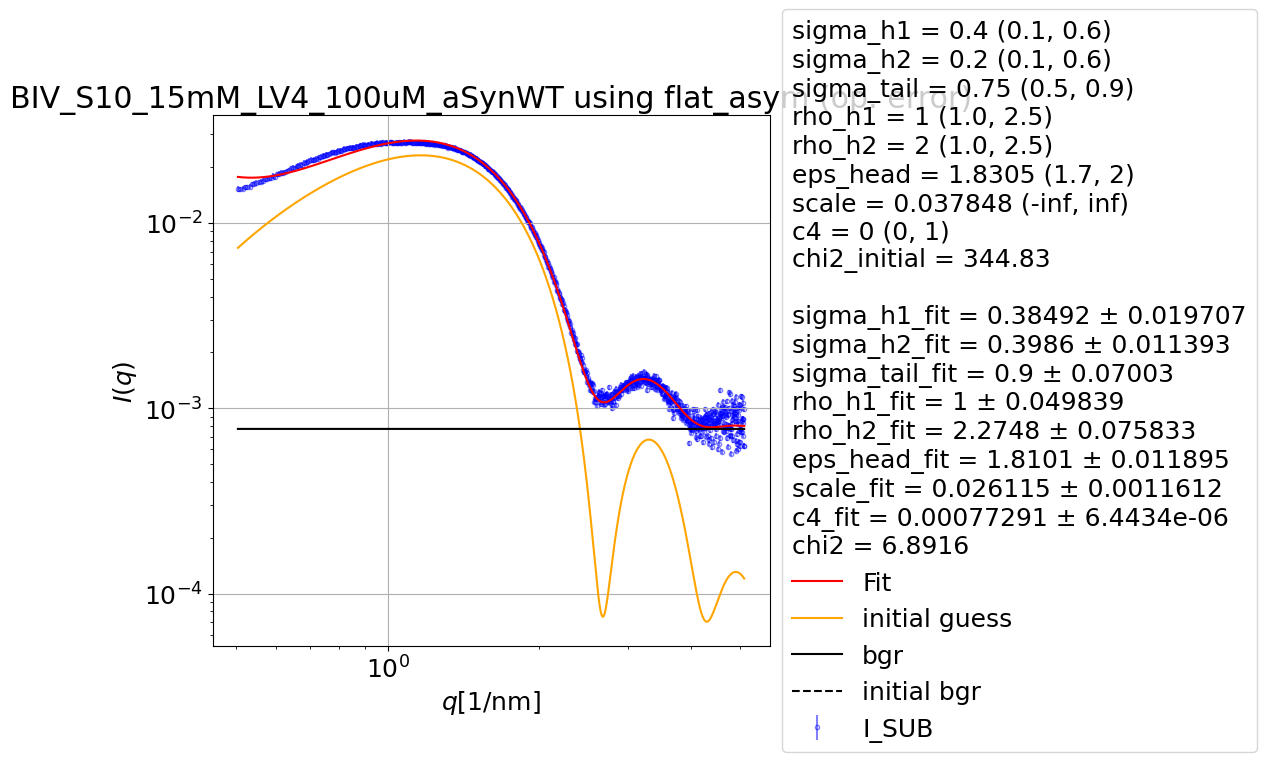

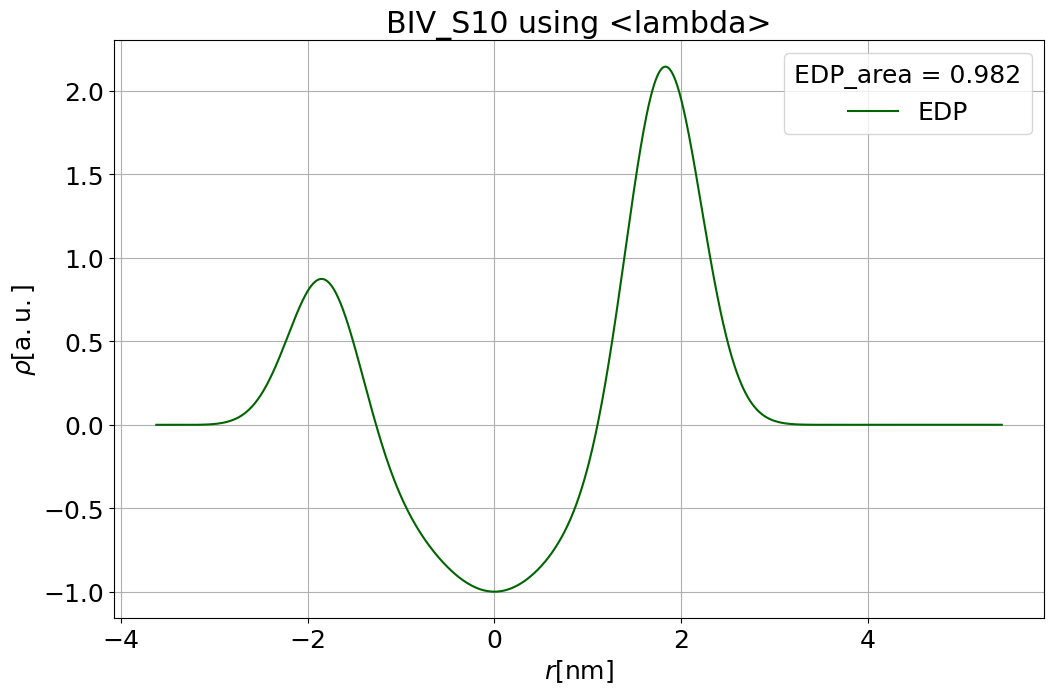

In [ ]:
# FLAT ASYM HIGH-Q FITTING ###########################
who = [
    "BII_S9",
    "BIV_S8",
    "BIV_S9",
    "BIV_S10"
]

for sample in who:   
    # sample = "BIV_S10"
    print(aesthetics_dict[sample][0])
    block = sample.split("_")[0]
    block_path = BM29.blockpath(block)
    dir_names = [x.name for x in block_path.iterdir()]
    for dir_name in dir_names:
        if dir_name[:-13].endswith(sample):
            sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
            q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)

    mask = (q >= 0.5) & (q <= 5.1)
    q    = q[mask]
    I    = I[mask]
    Ierr = Ierr[mask]
    Ierr_op = BM29.op_error_classic(q, I) 

    fit_function = lambda q, sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2,   eps_head,       scale, c4: fit.ULV_flat_asym(q, sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2,   eps_head,       scale,      0, 0, c4)
    plt.close("all")

    q     = q
    I     = I
    I_err = np.abs(I / 30) #Ierr

    # ========================== Parameters ==========================
    R       = 0
    sigma_R = 0

    sigma_h1 = 0.4
    sigma_h2 = 0.2
    sigma_tail = 0.75 
    rho_h1 = 1
    rho_h2 = 2
    eps_head = 1.8305 
    scale = 0.037848 

    c2    = 0
    c3    = 0
    c4    = 0
    # ========================== Setting Bounds ==============================

    p0           = [sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2,   eps_head,       scale,  c4] #,      c2,      c3,      c4]
    lower_bounds = [    0.10,     0.10,        0.5,    1.0,    1.0,        1.7,     -np.inf,   0] #,       0,       0,       0]
    upper_bounds = [     0.6,      0.6,        0.9,    2.5,    2.5,          2,     +np.inf,   1] #,   1e-10,   1e-10,   1e-10]

    #======================== Fit ===========================================
    popt, pcov = curve_fit(fit_function, q, I, sigma=I_err, maxfev=20000, p0=p0, bounds = (lower_bounds, upper_bounds))

    param_names = ["sigma_h1_fit", "sigma_h2_fit", "sigma_tail_fit", "rho_h1_fit", "rho_h2_fit", "eps_head_fit", "scale_fit", "c4_fit"]

    perr = np.sqrt(np.diag(pcov))
    fit_lib_entry = "["
    for name, value in zip(param_names, popt):
        globals()[name] = value
        fit_lib_entry += f"{value:.4g}, "
    fit_lib_entry = fit_lib_entry[:-2]
    fit_lib_entry += "]"
    print(fit_lib_entry)
    chi2, info_text = fit.info(q, I, I_err, param_names, p0, popt, perr, fit_function)

    residuals = I - fit_function(q, *p0)
    initial_chi2 = np.sum((residuals / I_err)**2) / (len(I) - len(p0) - 1)
    names2 = [name[:-4] for name in param_names]
    info_text2 = "\n".join(f"{name} = {val:.5g} ({lower_bounds[i]}, {upper_bounds[i]})" for name, val, i in zip(names2, p0, range(len(p0))))
    info_text2 += f"\nchi2_initial = {initial_chi2:.5g}\n \n"

    info_text_print = info_text2 + info_text
    #=========================== Plot ===========================================

    q_fit = np.linspace(min(q), max(q), 10000)
    plt.figure(figsize=(12, 7.5))
    plt.errorbar(q, I, I_err, marker="o", markersize=3,markeredgewidth=1,ecolor="Blue",      markeredgecolor='Blue',      markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
    plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
    plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
    plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, 0, 0, c4_fit), color='black', label='bgr')
    plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, 0, 0, c4), color='black', label='initial bgr', ls="--")

    plt.xlabel('$q [1/\\mathrm{nm}]$')
    plt.ylabel('$I(q)$')
    plt.title(f'{BM29.sample_dict[sample]} using flat_asym (op. error)')
    plt.grid(True)
    legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
    legend.set_title(info_text_print)
    plt.tight_layout()
    # plt.savefig(target_folder / f"{fit_function.__name__}_operative_error_2.png",dpi=400, bbox_inches='tight', pad_inches=0.05)
    plt.show()

    # =========== EDP =====================================================================================
    fig = fit.EDP_plot(0, sigma_h1_fit, sigma_h2_fit, sigma_tail_fit, rho_h1_fit, rho_h2_fit, eps_head_fit, eps_head_fit, info_text, 
                f'{sample} using {fit_function.__name__}')
    plt.show(fig)
    # # fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_op_error_2.png", dpi=400, bbox_inches='tight', pad_inches=0.05)
    # fig = fit.EDP_plot(0, sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2, eps_head, eps_head, info_text, 
    #                    f'{sample} using {fit_function.__name__} (initial guess)')
    # fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_INITIAL GUESS_op_error_2.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

    # pow_law_reality_check(c2_fit, c3_fit, c4_fit)



For sample 15 mM LVs + 50 µM aSyn
EDP total    : 0.5781
EDP HG       : 2.0296
EDP TG       : 1.4515
HG asymmetry : 0.4287
HG/TG ratio  : 1.3983
For sample 15 mM LVs + 75 µM aSyn
EDP total    : 1.0217
EDP HG       : 2.5426
EDP TG       : 1.5209
HG asymmetry : 0.4868
HG/TG ratio  : 1.6718
For sample 15 mM LVs + 100 µM aSyn
EDP total    : 1.3050
EDP HG       : 2.8683
EDP TG       : 1.5633
HG asymmetry : 0.5306
HG/TG ratio  : 1.8348


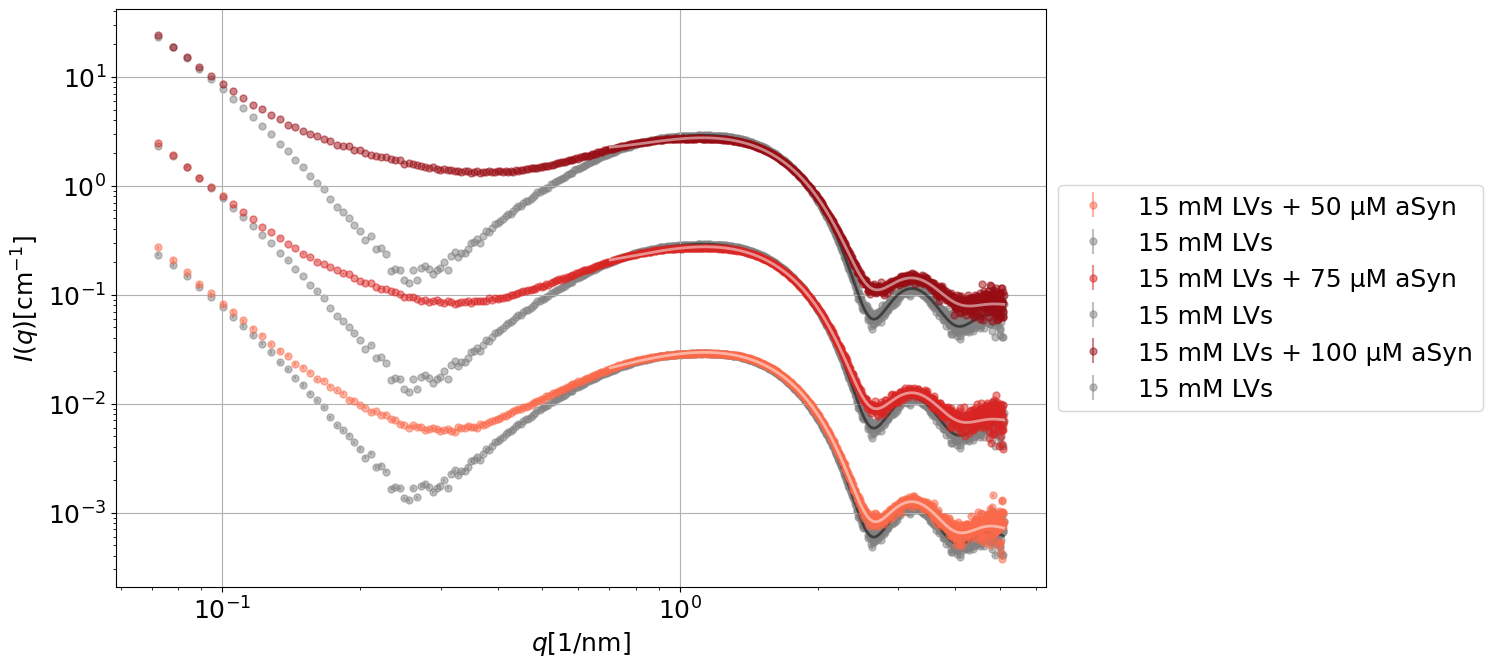

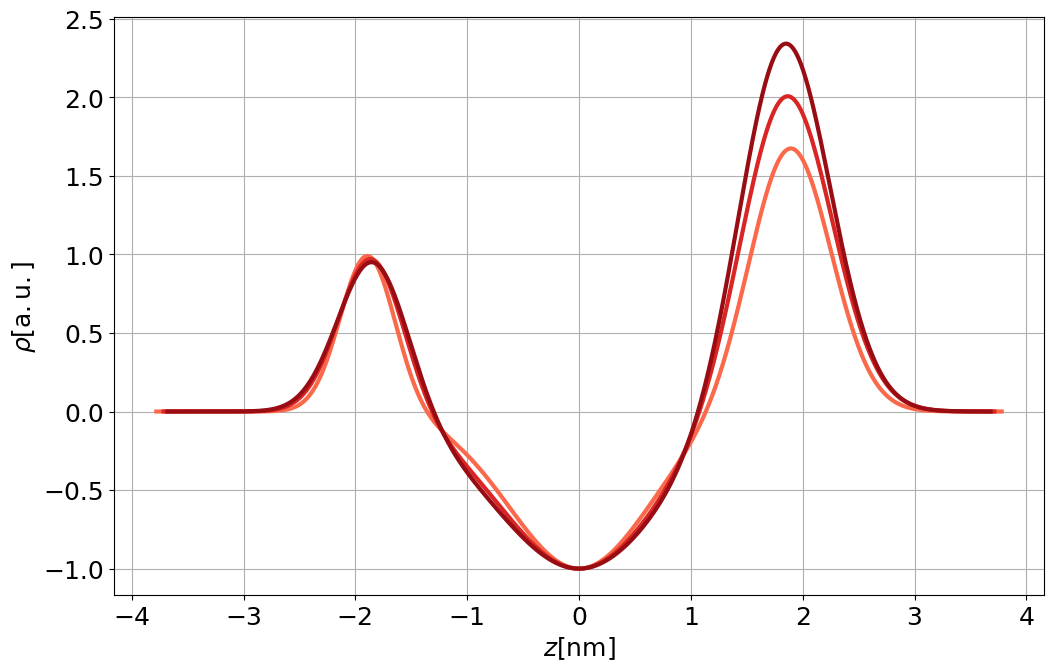

In [ ]:
# Fig 7 with Flat asym
who = [
    "BIV_S8",
    "BIV_S9",
    "BIV_S10"
]

fit_function = lambda q, sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2,   eps_head,       scale, c4: fit.ULV_flat_asym(q, sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2,   eps_head,       scale,      0, 0, c4)
fit_function_name = "flat_asym_C4_q0p7"
plt.close("all")

pure_sample = "BII_S9"
block = pure_sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(pure_sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[pure_sample]
        q_pure, I_pure, Ierr_pure = np.loadtxt(sub_dat_path, unpack=True)
    
mask = (q_pure >= 0.07) & (q_pure <= 5.1)
mask2 = (q_pure >= 0.7) & (q_pure <= 5.1)
q_pure_fit = np.copy(q_pure[mask2])
q_pure    = q_pure[mask]
I_pure    = I_pure[mask]
Ierr_pure = Ierr_pure[mask]
Ierr_pure_op = BM29.op_error_classic(q_pure, I_pure) 
I_fit_pure = fit_function(q_pure_fit, *BM29.best_fits[pure_sample][fit_function_name][1])

f = plt.figure(figsize=(12, 7.5))
for i, sample in enumerate(who):
    block = sample.split("_")[0]
    block_path = BM29.blockpath(block)
    dir_names = [x.name for x in block_path.iterdir()]
    for dir_name in dir_names:
        if dir_name[:-13].endswith(sample):
            sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
            q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)
    
    mask = (q >= 0.07) & (q <= 5.1)
    mask2 = (q >= 0.7) & (q <= 5.1)
    q_fit = np.copy(q[mask2])
    q    = q[mask]
    I    = I[mask]
    Ierr = Ierr[mask]
    Ierr_op = BM29.op_error_classic(q, I) 

    I_fit = fit_function(q_fit, *BM29.best_fits[sample][fit_function_name][1])
    plt.errorbar(q, 10**(i) * I, Ierr_op, marker="o", markersize=5, ecolor=aesthetics_dict[sample][1], color=aesthetics_dict[sample][1], markeredgewidth=1, alpha=0.5, ls="None", label=aesthetics_dict[sample][0], zorder=8) 
    plt.loglog(q_fit, 10**(i) *  I_fit, color="white", alpha=0.5, lw=2, zorder=10)
    plt.errorbar(q, 10**(i) * I_pure, Ierr_pure_op, marker="o", markersize=5, ecolor=aesthetics_dict[pure_sample][1], color=aesthetics_dict[pure_sample][1], markeredgewidth=1, alpha=0.5, ls="None", label=aesthetics_dict[pure_sample][0], zorder=1) 
    plt.loglog(q_pure_fit, 10**(i) *  I_fit_pure, color="black", lw=2, alpha=0.5)

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q) [\\mathrm{cm}^{-1}]$')
plt.grid()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')

fig = EDP_plot("flat_asym_C4_q0p7", who, aesthetics_dict)

target_folder = Path("C:/Users/riko05/Documents/8. SoSe 26/Code/BM29_data_and_analysis_2026/analysis_BM29_July2026/Results_and_Figures/Aug24/Figure_7")
fig.savefig(target_folder / "EDPs_FLAT_ASYM_Fig7.png", dpi=400, bbox_inches='tight', pad_inches=0.05)
f.savefig(target_folder / "Curves_and_Fits_FLAT_ASYM_Fig7.png", dpi=400, bbox_inches='tight', pad_inches=0.05)